# How Grid Position Affects Race Result

This notebook asks a simple question: **does starting closer to the front usually lead to a better finishing position?**

The goal is to make the analysis simple and easy to follow.

I will:

- load the prepared Formula 1 race dataset I made using F1 Api.
- clean the data so it is ready for modeling
- visualize the relationship between starting and finishing position
- train four regression models
- tune one model with GridSearchCV
- compare predictions and error metrics
- summarize what the model results tell us.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.2f}")

# Load the prepared race dataset
raw_df = pd.read_csv("f1_start_vs_finish.csv")
print("Rows and columns:", raw_df.shape)
display(raw_df.head())

# Keep the columns used in the analysis
analysis_df = raw_df[["start_position", "finish_position", "rainfall", "safety_car", "st_speed", "lane_duration", "circuit_type", "compound"]].copy()

analysis_df["start_position"] = pd.to_numeric(analysis_df["start_position"], errors="coerce")
analysis_df["finish_position"] = pd.to_numeric(analysis_df["finish_position"], errors="coerce")
analysis_df["safety_car"] = pd.to_numeric(analysis_df["safety_car"], errors="coerce")
analysis_df["st_speed"] = pd.to_numeric(analysis_df["st_speed"], errors="coerce")
analysis_df["lane_duration"] = pd.to_numeric(analysis_df["lane_duration"], errors="coerce")

# Convert rainfall into a simple 0/1 flag
rainfall_text = analysis_df["rainfall"].astype(str).str.strip().str.lower()
analysis_df["rainfall_flag"] = np.where(rainfall_text.isin(["1", "true", "yes", "y", "t"]), 1, 0)
analysis_df.loc[analysis_df["rainfall"].isna(), "rainfall_flag"] = 0
analysis_df["rainfall_flag"] = analysis_df["rainfall_flag"].astype(int)

# Clean the categorical race-context fields
analysis_df["circuit_type"] = analysis_df["circuit_type"].fillna("Unknown").astype(str).str.strip()
analysis_df["compound"] = analysis_df["compound"].fillna("Unknown").astype(str).str.strip()

# Fill missing values in the numeric race-context fields
analysis_df["safety_car"] = analysis_df["safety_car"].fillna(0).astype(int)
st_speed_median = analysis_df["st_speed"].median()
if pd.isna(st_speed_median):
    st_speed_median = 0
lane_duration_median = analysis_df["lane_duration"].median()
if pd.isna(lane_duration_median):
    lane_duration_median = 0
analysis_df["st_speed"] = analysis_df["st_speed"].fillna(st_speed_median)
analysis_df["lane_duration"] = analysis_df["lane_duration"].fillna(lane_duration_median)

# Remove rows that cannot be used in the regression models
analysis_df = analysis_df.dropna(subset=["start_position", "finish_position"]).copy()
analysis_df = analysis_df[(analysis_df["start_position"] > 0) & (analysis_df["finish_position"] > 0)]

# Make the positions easier to read
analysis_df["start_position"] = analysis_df["start_position"].astype(int)
analysis_df["finish_position"] = analysis_df["finish_position"].astype(int)

print("Rows after cleaning:", analysis_df.shape[0])
print("Missing values after cleaning:")
display(analysis_df[["start_position", "finish_position", "rainfall_flag", "safety_car", "st_speed", "lane_duration", "circuit_type", "compound"]].isna().sum())
print("Position summary:")
display(analysis_df[["start_position", "finish_position", "rainfall_flag", "safety_car", "st_speed", "lane_duration"]].describe())
print("Unique circuit types:", analysis_df["circuit_type"].nunique())
print("Unique compounds:", analysis_df["compound"].nunique())

Rows and columns: (2234, 14)


,session_key,driver_number,driver_acronym,team_name,circuit_short_name,circuit_type,championship_position_start,start_position,finish_position,rainfall,safety_car,compound,st_speed,lane_duration
0,7953,1,VER,Red Bull Racing,Sakhir,Permanent,NaN,1,1.00,False,1.00,SOFT,303.00,NaN
1,7953,11,PER,Red Bull Racing,Sakhir,Permanent,NaN,2,2.00,False,1.00,SOFT,330.00,NaN
2,7953,16,LEC,Ferrari,Sakhir,Permanent,NaN,3,NaN,False,1.00,SOFT,324.00,NaN
3,7953,55,SAI,Ferrari,Sakhir,Permanent,NaN,4,4.00,False,1.00,SOFT,324.00,NaN
4,7953,14,ALO,Aston Martin,Sakhir,Permanent,NaN,5,3.00,False,1.00,SOFT,328.00,NaN


Rows after cleaning: 2003
Missing values after cleaning:


start_position     0
finish_position    0
rainfall_flag      0
safety_car         0
st_speed           0
lane_duration      0
circuit_type       0
compound           0
dtype: int64

Position summary:


,start_position,finish_position,rainfall_flag,safety_car,st_speed,lane_duration
count,2003.00,2003.00,2003.00,2003.00,2003.00,2003.00
mean,10.31,9.54,0.24,0.41,322.66,116.39
std,5.78,5.31,0.43,0.49,14.32,336.06
min,1.00,1.00,0.00,0.00,271.00,19.81
25%,5.00,5.00,0.00,0.00,317.00,42.50
50%,10.00,9.00,0.00,0.00,324.00,44.75
75%,15.00,14.00,0.00,1.00,331.00,46.80
max,20.00,20.00,1.00,1.00,364.00,2435.80


Unique circuit types: 3
Unique compounds: 6


## Cleaning the data

My CSV file includes race results plus extra context (weather, circuit type, and tyre compound).
For the core target variable, we predict `finish_position`.

Before modeling, I:

- convert position fields to numeric values
- remove rows with missing target or invalid position values
- standardize helper fields such as rainfall flags and category labels

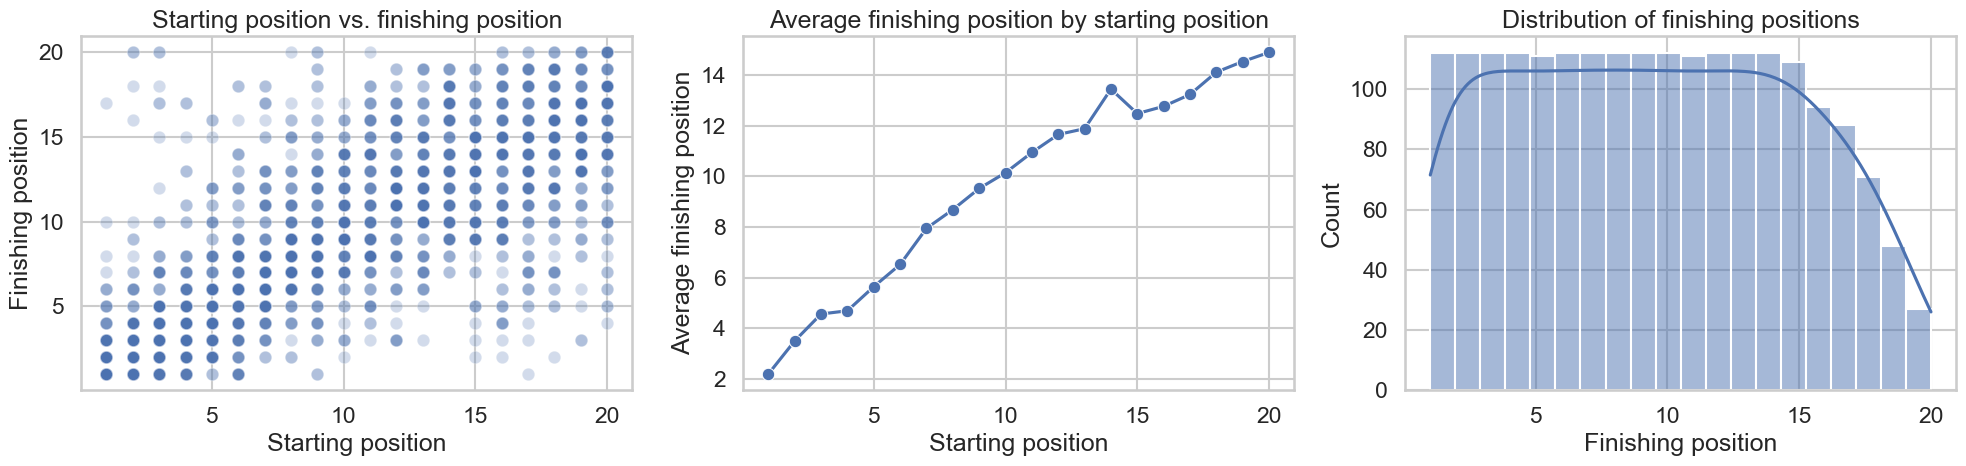

Correlation between start and finish position: 0.722


,start_position,finish_position
0,1,2.20
1,2,3.50
2,3,4.57
3,4,4.69
4,5,5.65
5,6,6.52
6,7,7.95
7,8,8.69
8,9,9.53
9,10,10.15


In [2]:
# Plot the relationship between grid position and finishing position
average_finish = analysis_df.groupby("start_position", as_index=False)["finish_position"].mean()
correlation = analysis_df["start_position"].corr(analysis_df["finish_position"])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sample_size = min(len(analysis_df), 2000)
sample_for_plot = analysis_df.sample(sample_size, random_state=42) if sample_size > 0 else analysis_df

sns.scatterplot(
    data=sample_for_plot,
    x="start_position",
    y="finish_position",
    alpha=0.25,
    ax=axes[0],
)
axes[0].set_title("Starting position vs. finishing position")
axes[0].set_xlabel("Starting position")
axes[0].set_ylabel("Finishing position")

# Show the average finish by starting spot
sns.lineplot(data=average_finish, x="start_position", y="finish_position", marker="o", ax=axes[1])
axes[1].set_title("Average finishing position by starting position")
axes[1].set_xlabel("Starting position")
axes[1].set_ylabel("Average finishing position")

# Inspect the spread of finishing positions
sns.histplot(analysis_df["finish_position"], bins=20, kde=True, ax=axes[2])
axes[2].set_title("Distribution of finishing positions")
axes[2].set_xlabel("Finishing position")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Correlation between start and finish position: {correlation:.3f}")
display(average_finish.head(10))

## More race context

The next three charts look at the extra fields I added to the dataset.
They help answer a few simple follow-up questions: do different circuit types behave differently, does rain change the outcome, and do tyre compounds show different finishing patterns?

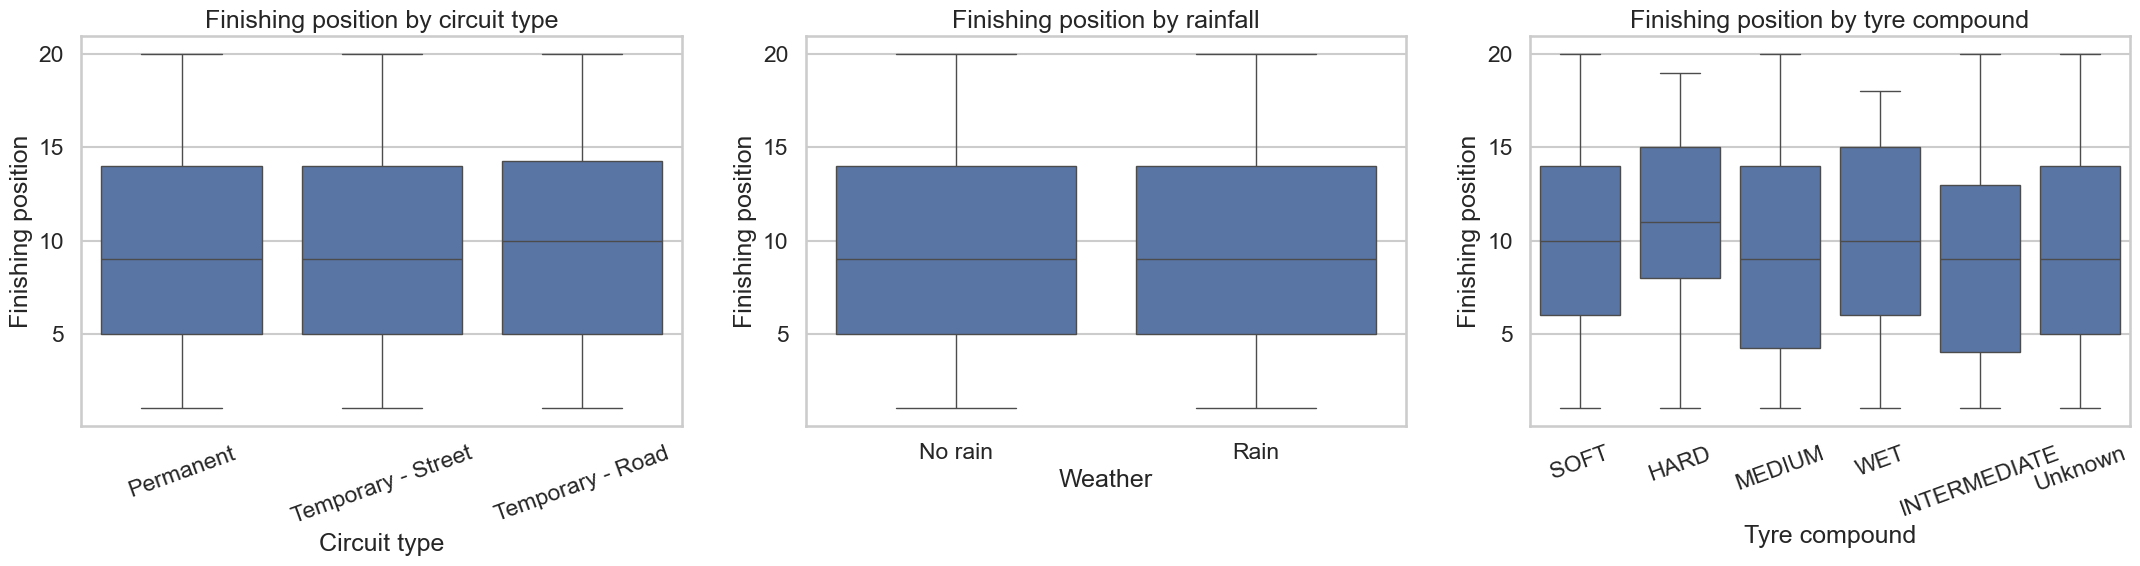

Average finishing position by circuit type:


,circuit_type,finish_position
2,Temporary - Street,9.41
0,Permanent,9.54
1,Temporary - Road,9.85


Average finishing position by rainfall:


,rainfall_label,finish_position
0,No rain,9.57
1,Rain,9.43


Average finishing position by tyre compound:


,compound,finish_position
1,INTERMEDIATE,8.90
2,MEDIUM,9.25
4,Unknown,9.54
3,SOFT,9.97
5,WET,10.35
0,HARD,11.36


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

sns.boxplot(data=analysis_df, x="circuit_type", y="finish_position", ax=axes[0])
axes[0].set_title("Finishing position by circuit type")
axes[0].set_xlabel("Circuit type")
axes[0].set_ylabel("Finishing position")
axes[0].tick_params(axis="x", rotation=20)

rainfall_plot = analysis_df.copy()
rainfall_plot["rainfall_label"] = rainfall_plot["rainfall_flag"].map({0: "No rain", 1: "Rain"})
sns.boxplot(data=rainfall_plot, x="rainfall_label", y="finish_position", ax=axes[1])
axes[1].set_title("Finishing position by rainfall")
axes[1].set_xlabel("Weather")
axes[1].set_ylabel("Finishing position")

sns.boxplot(data=analysis_df, x="compound", y="finish_position", ax=axes[2])
axes[2].set_title("Finishing position by tyre compound")
axes[2].set_xlabel("Tyre compound")
axes[2].set_ylabel("Finishing position")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

print("Average finishing position by circuit type:")
display(analysis_df.groupby("circuit_type", as_index=False)["finish_position"].mean().sort_values("finish_position"))

print("Average finishing position by rainfall:")
display(rainfall_plot.groupby("rainfall_label", as_index=False)["finish_position"].mean())

print("Average finishing position by tyre compound:")
display(analysis_df.groupby("compound", as_index=False)["finish_position"].mean().sort_values("finish_position"))

## Modeling approach

I used a compact set of features to predict `finish_position`:
`start_position`, `rainfall_flag`, `safety_car`, `st_speed`, `lane_duration`, `circuit_type`, and `compound`.

This keeps the model small enough to be manageable while also including what I think are the biggest factors.

The four regression models are:

- Linear Regression
- KNN
- Decision Tree
- Random Forest

In [4]:
# Build features and target
feature_columns = [
    "start_position",
    "rainfall_flag",
    "safety_car",
    "st_speed",
    "lane_duration",
    "circuit_type",
    "compound",
]
X = analysis_df[feature_columns].copy()
y = analysis_df["finish_position"]

# One-hot encode categorical inputs
X_encoded = pd.get_dummies(X, columns=["circuit_type", "compound"])

# Train/test split (shared by all models)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
)

# Baseline models
models = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=200),
}

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "mse": mse,
        "rmse": np.sqrt(mse),
        "r2": r2_score(y_true, y_pred),
    }

results = []
fitted_models = {}

for model_name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    results.append({"model": model_name, **regression_metrics(y_test, preds)})
    fitted_models[model_name] = model

results_df = pd.DataFrame(results).sort_values("rmse").reset_index(drop=True)
display(results_df)
print(f"Best base model by RMSE: {results_df.iloc[0]['model']}")

,model,mae,mse,rmse,r2
0,Random Forest,2.82,13.06,3.61,0.57
1,Linear Regression,2.81,13.15,3.63,0.56
2,KNN,2.88,13.53,3.68,0.55
3,Decision Tree,3.19,19.06,4.37,0.37


Best base model by RMSE: Random Forest


,model,mae,mse,rmse,r2
0,Random Forest (tuned),2.74,12.19,3.49,0.59
1,Random Forest,2.82,13.06,3.61,0.57
2,Linear Regression,2.81,13.15,3.63,0.56
3,KNN,2.88,13.53,3.68,0.55
4,Decision Tree,3.19,19.06,4.37,0.37


Best model overall: Random Forest (tuned)
Best test RMSE: 3.49
Best test MAE: 2.74


,start_position,rainfall_flag,safety_car,st_speed,lane_duration,circuit_type,compound,predicted_finish_position,historical_average_finish
0,1,0,0,324.00,44.75,Permanent,MEDIUM,1.71,2.20
1,2,0,0,324.00,44.75,Permanent,MEDIUM,3.49,3.50
2,3,0,0,324.00,44.75,Permanent,MEDIUM,4.48,4.57
3,4,0,0,324.00,44.75,Permanent,MEDIUM,4.72,4.69
4,5,0,0,324.00,44.75,Permanent,MEDIUM,5.64,5.65
5,6,0,0,324.00,44.75,Permanent,MEDIUM,6.44,6.52
6,7,0,0,324.00,44.75,Permanent,MEDIUM,7.11,7.95
7,8,0,0,324.00,44.75,Permanent,MEDIUM,8.45,8.69
8,9,0,0,324.00,44.75,Permanent,MEDIUM,9.81,9.53
9,10,0,0,324.00,44.75,Permanent,MEDIUM,10.75,10.15


Model-based optimal starting position: 1
Predicted finishing position at that start: 1.71
Reference conditions used for the curve: rainfall=0, safety_car=0, st_speed=324.00, lane_duration=44.75, circuit_type=Permanent, compound=MEDIUM


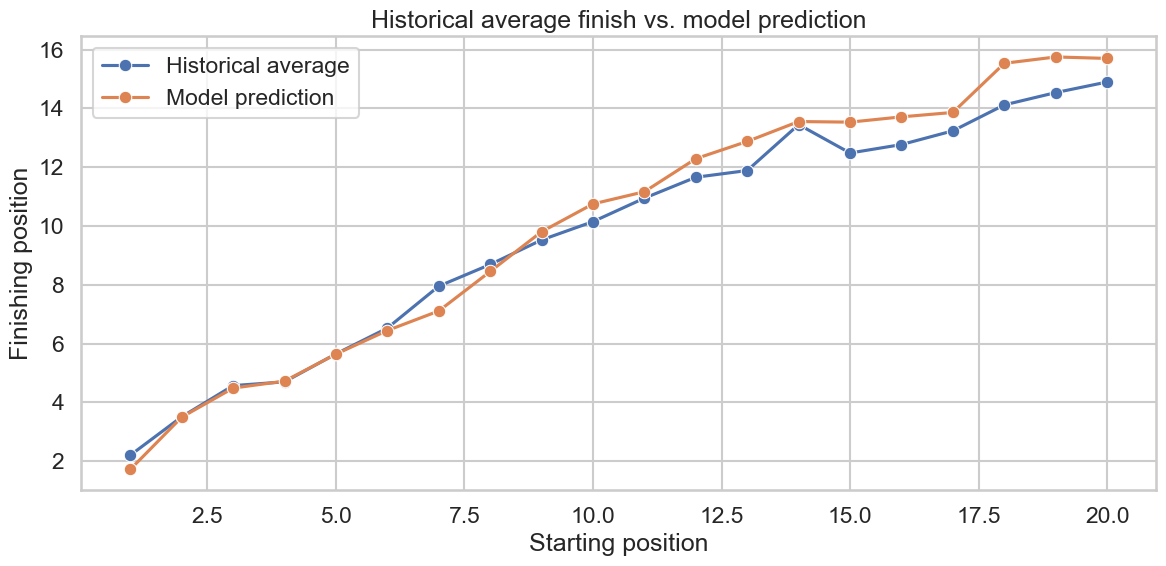

In [5]:
# Tune the random forest with a small grid search
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 4, 8],
    "min_samples_leaf": [1, 2],
}

rf_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=rf_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

tuned_rf = rf_search.best_estimator_
tuned_result = {
    "model": "Random Forest (tuned)",
    **regression_metrics(y_test, tuned_rf.predict(X_test)),
}

results_df = pd.concat([results_df, pd.DataFrame([tuned_result])], ignore_index=True)
results_df = results_df.sort_values("rmse").reset_index(drop=True)
display(results_df)

best_result = results_df.iloc[0]
print(f"Best model overall: {best_result['model']}")
print(f"Best test RMSE: {best_result['rmse']:.2f}")
print(f"Best test MAE: {best_result['mae']:.2f}")

# Predict finish position across the grid while holding other inputs constant
reference_rainfall_flag = int(analysis_df["rainfall_flag"].mode().iloc[0])
reference_safety_car = int(analysis_df["safety_car"].mode().iloc[0])
reference_st_speed = float(analysis_df["st_speed"].median())
reference_lane_duration = float(analysis_df["lane_duration"].median())
reference_circuit_type = analysis_df["circuit_type"].mode().iloc[0]
reference_compound = analysis_df["compound"].mode().iloc[0]

start_range = pd.DataFrame(
    {
        "start_position": np.arange(analysis_df["start_position"].min(), analysis_df["start_position"].max() + 1)
    }
)
start_range["rainfall_flag"] = reference_rainfall_flag
start_range["safety_car"] = reference_safety_car
start_range["st_speed"] = reference_st_speed
start_range["lane_duration"] = reference_lane_duration
start_range["circuit_type"] = reference_circuit_type
start_range["compound"] = reference_compound
start_range_encoded = pd.get_dummies(start_range, columns=["circuit_type", "compound"])
start_range_encoded = start_range_encoded.reindex(columns=X_encoded.columns, fill_value=0)

best_model = tuned_rf if best_result["model"] == "Random Forest (tuned)" else fitted_models[best_result["model"]]

prediction_table = start_range.copy()
prediction_table["predicted_finish_position"] = best_model.predict(start_range_encoded)
prediction_table["historical_average_finish"] = prediction_table["start_position"].map(
    analysis_df.groupby("start_position")["finish_position"].mean()
)

display(prediction_table.head(10))

optimal_row = prediction_table.loc[prediction_table["predicted_finish_position"].idxmin()]
print(f"Model-based optimal starting position: {int(optimal_row['start_position'])}")
print(f"Predicted finishing position at that start: {optimal_row['predicted_finish_position']:.2f}")
print(
    f"Reference conditions used for the curve: rainfall={reference_rainfall_flag}, "
    f"safety_car={reference_safety_car}, st_speed={reference_st_speed:.2f}, lane_duration={reference_lane_duration:.2f}, "
    f"circuit_type={reference_circuit_type}, compound={reference_compound}"
)

fig, ax = plt.subplots(figsize=(12, 6))
sns.lineplot(data=prediction_table, x="start_position", y="historical_average_finish", marker="o", label="Historical average", ax=ax)
sns.lineplot(data=prediction_table, x="start_position", y="predicted_finish_position", marker="o", label="Model prediction", ax=ax)
ax.set_title("Historical average finish vs. model prediction")
ax.set_xlabel("Starting position")
ax.set_ylabel("Finishing position")
ax.legend()
plt.tight_layout()
plt.show()

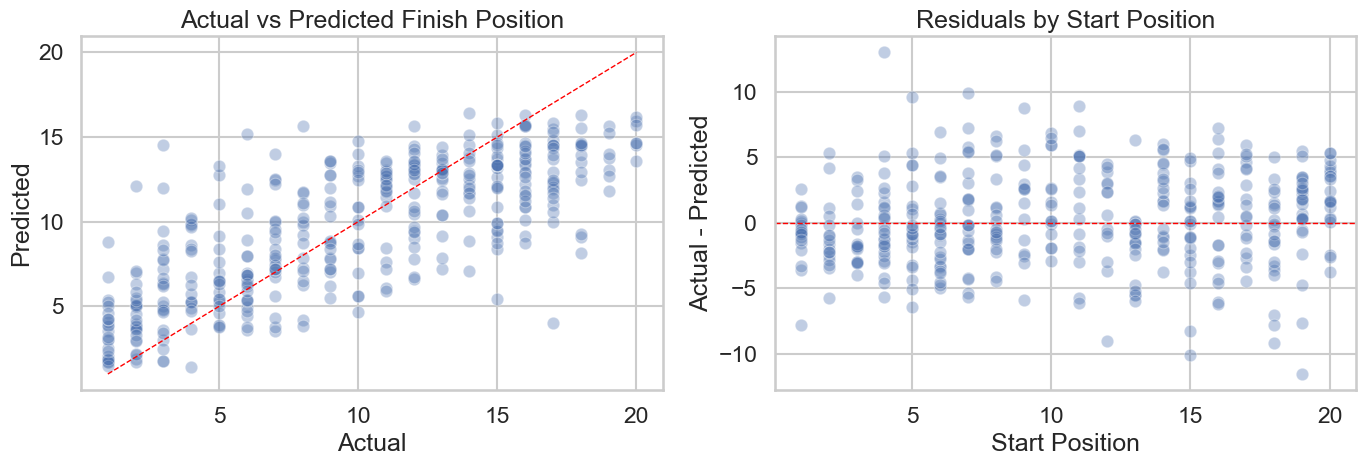

In [6]:
# Model diagnostics for the selected best model
y_pred_test = best_model.predict(X_test)
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1) Actual vs Predicted
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.35, ax=axes[0])
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "--", color="red", linewidth=1)
axes[0].set_title("Actual vs Predicted Finish Position")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

# 2) Residual pattern
residual_df = pd.DataFrame({
    "start_position": X_test["start_position"],
    "residual": residuals
})
sns.scatterplot(data=residual_df, x="start_position", y="residual", alpha=0.35, ax=axes[1])
axes[1].axhline(0, linestyle="--", color="red", linewidth=1)
axes[1].set_title("Residuals by Start Position")
axes[1].set_xlabel("Start Position")
axes[1].set_ylabel("Actual - Predicted")

plt.tight_layout()
plt.show()

The diagnostic plots show that predictions generally follow actual finishing positions, while residuals cluster around zero with some spread, suggesting the model captures the main trend but still misses race-specific variability.

Estimated input impact on model predictions (higher means more influence):


,input,impact_score,impact_percent
0,start_position,3.20,93.53
1,lane_duration,0.13,3.90
2,st_speed,0.06,1.71
3,safety_car,0.03,0.86
4,rainfall,0.00,0.00
5,compound,0.00,0.00
6,circuit_type,0.00,0.00


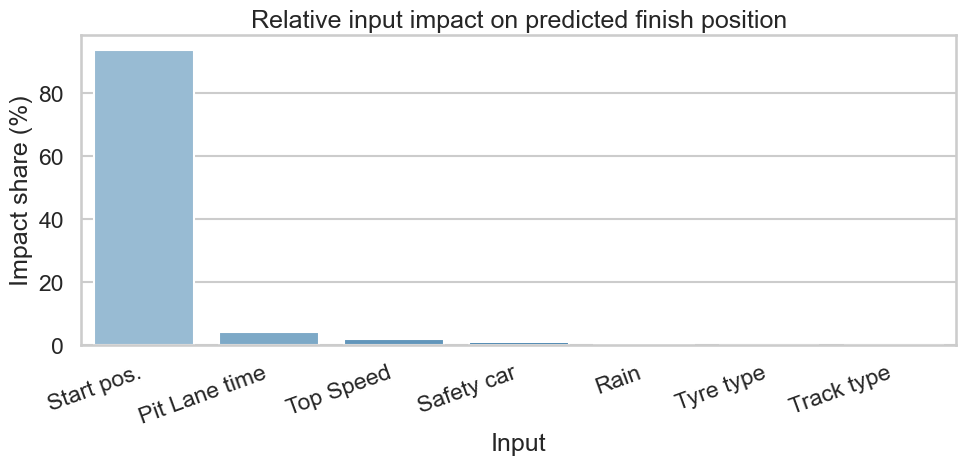

In [7]:
# Estimate how much each input affects predictions using permutation importance
perm = permutation_importance(
    estimator=best_model,
    X=X_test,
    y=y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_root_mean_squared_error",
)

importance_df = pd.DataFrame({"feature": X_test.columns, "importance_mean": perm.importances_mean})

# Group dummy columns back to their original inputs

def original_input_name(feature_name: str) -> str:
    if feature_name == "start_position":
        return "start_position"
    if feature_name == "rainfall_flag":
        return "rainfall"
    if feature_name == "safety_car":
        return "safety_car"
    if feature_name.startswith("circuit_type_"):
        return "circuit_type"
    if feature_name.startswith("compound_"):
        return "compound"
    return feature_name

importance_df["input"] = importance_df["feature"].apply(original_input_name)
input_impact = (
    importance_df.groupby("input", as_index=False)["importance_mean"]
    .sum()
    .rename(columns={"importance_mean": "impact_score"})
)

# Clip negative scores so the chart stays easy to read
input_impact["impact_score"] = input_impact["impact_score"].clip(lower=0)
input_impact = input_impact.sort_values("impact_score", ascending=False).reset_index(drop=True)

# Convert the scores into percentage shares
total_impact = input_impact["impact_score"].sum()
if total_impact > 0:
    input_impact["impact_percent"] = 100 * input_impact["impact_score"] / total_impact
else:
    input_impact["impact_percent"] = 0

# Use shorter labels in the chart so the axis stays readable
label_map = {
    "start_position": "Start pos.",
    "rainfall": "Rain",
    "safety_car": "Safety car",
    "circuit_type": "Track type",
    "compound": "Tyre type",
    "lane_duration": "Pit Lane time",
    "st_speed": "Top Speed"
}
input_impact["input_label"] = input_impact["input"].map(label_map).fillna(input_impact["input"])

print("Estimated input impact on model predictions (higher means more influence):")
display(input_impact[["input", "impact_score", "impact_percent"]])

plt.figure(figsize=(10, 5))
sns.barplot(data=input_impact, x="input_label", y="impact_percent", hue="input_label", legend=False, palette="Blues_d")
plt.title("Relative input impact on predicted finish position")
plt.xlabel("Input")
plt.ylabel("Impact share (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## Final reflection

My model uses: starting position, rainfall, safety car presence, top speed, pit lane time, track type, and tyre type to predict finishing position.

I feel like this was a lot of (albeit fun) work to determine what most of us could have assumed; Better starting position = better finishing position.

I was surprised that track type didn't feature in at all. I would have thought street circuits would allow for more passing than some of the more traditional tracks. 

I ran out of time (API calls were taking 15 minutes or more likely due to my crap spaghetti code calls) to pull and cleanup more data such as drivers championship points which might have given us some insight that higher scoring drivers tend to "float to the top of the pack"




